# Datheon Internship — Task 1
## Multi-Class Benchmark Classification Pipeline (Iris Dataset)

**Objective:** Build and evaluate supervised classification pipelines using Scikit-Learn, StandardScaler, an 80/20 train-test split, Logistic Regression, and Decision Tree.

**Deliverables covered**
- Dataset loading and exploratory data analysis
- Pairplot visualization
- Feature scaling without data leakage
- Logistic Regression and Decision Tree benchmarks
- Accuracy, precision, recall, F1-score, and classification reports
- Confusion-matrix heatmaps
- Decision-boundary visualization using two features

**Dataset:** Iris dataset from the Seaborn data repository. The notebook also includes a fallback to Scikit-Learn's built-in Iris dataset if the CSV cannot be downloaded.


## 1. Import libraries

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

RANDOM_STATE = 42
sns.set_theme(style="whitegrid", context="notebook")

print("Libraries imported successfully.")

Libraries imported successfully.


## 2. Load the Iris dataset

In [2]:
DATA_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"

try:
    df = pd.read_csv(DATA_URL)
    print("Loaded Iris dataset from the provided CSV URL.")
except Exception as exc:
    print(f"Could not download CSV ({exc}). Using Scikit-Learn's built-in copy instead.")
    iris = load_iris(as_frame=True)
    df = iris.frame.rename(columns={
        "sepal length (cm)": "sepal_length",
        "sepal width (cm)": "sepal_width",
        "petal length (cm)": "petal_length",
        "petal width (cm)": "petal_width",
        "target": "target"
    })
    target_names = dict(enumerate(iris.target_names))
    df["species"] = df["target"].map(target_names)
    df = df.drop(columns="target")

df.head()

Loaded Iris dataset from the provided CSV URL.


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


## 3. Inspect and validate the data

In [3]:
print("Dataset shape:", df.shape)
display(df.head())
print("\\nColumn data types:")
display(df.dtypes.to_frame("dtype"))
print("\\nMissing values per column:")
display(df.isna().sum().to_frame("missing_values"))
print("\\nDuplicate rows:", df.duplicated().sum())
print("\\nClass distribution:")
display(df["species"].value_counts().to_frame("count"))

Dataset shape: (150, 5)


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


\nColumn data types:


,dtype
sepal_length,float64
sepal_width,float64
petal_length,float64
petal_width,float64
species,object


\nMissing values per column:


,missing_values
sepal_length,0
sepal_width,0
petal_length,0
petal_width,0
species,0


\nDuplicate rows: 1
\nClass distribution:


,count
species,
setosa,50
versicolor,50
virginica,50


In [4]:
# Keep only rows with complete data for this benchmark.
df = df.dropna().copy()

feature_cols = [c for c in df.columns if c != "species"]
X = df[feature_cols].select_dtypes(include=np.number)
y = df["species"]

if X.shape[1] != 4:
    raise ValueError(f"Expected 4 numerical Iris features, found {X.shape[1]}.")

print("Features:", list(X.columns))
print("Target classes:", sorted(y.unique()))

Features: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Target classes: ['setosa', 'versicolor', 'virginica']


## 4. Exploratory Data Analysis (EDA)

,count,mean,std,min,25%,50%,75%,max
sepal_length,150.0,5.843333,0.828066,4.3,5.1,5.80,6.4,7.9
sepal_width,150.0,3.057333,0.435866,2.0,2.8,3.00,3.3,4.4
petal_length,150.0,3.758000,1.765298,1.0,1.6,4.35,5.1,6.9
petal_width,150.0,1.199333,0.762238,0.1,0.3,1.30,1.8,2.5


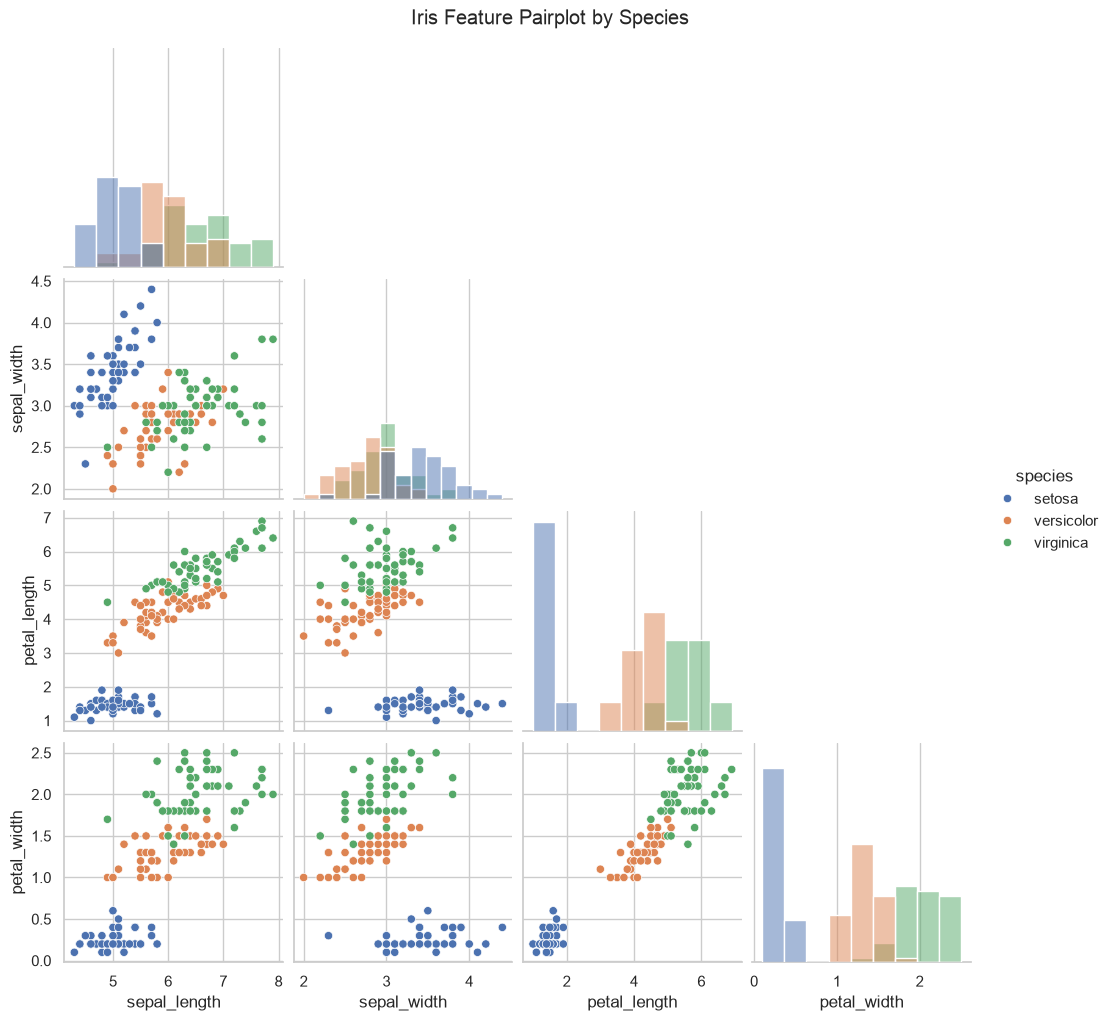

In [5]:
# Summary statistics
display(X.describe().T)

# Pairplot: useful for seeing class separation across feature pairs
eda_df = X.copy()
eda_df["species"] = y.values
sns.pairplot(eda_df, hue="species", diag_kind="hist", corner=True)
plt.suptitle("Iris Feature Pairplot by Species", y=1.02)
plt.show()

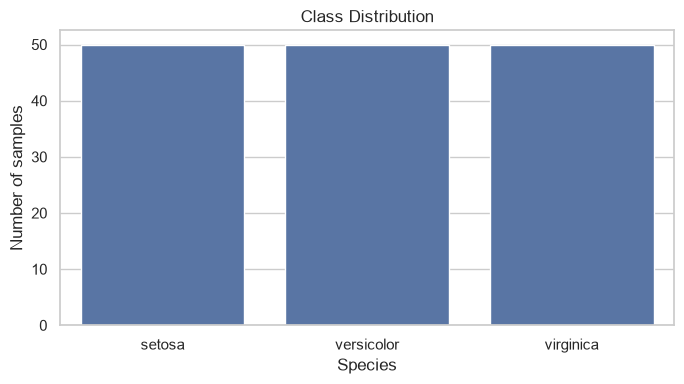

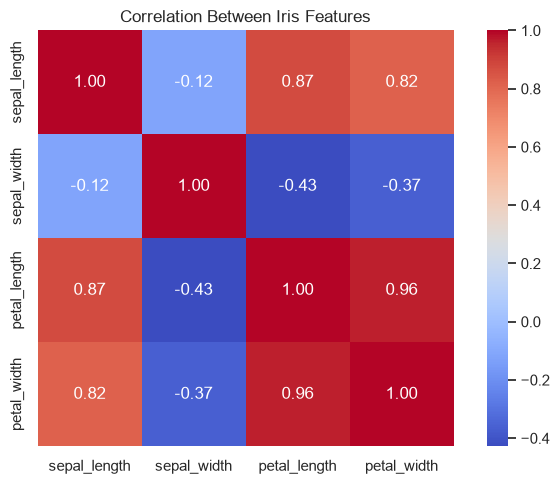

In [6]:
# Class counts
plt.figure(figsize=(7, 4))
sns.countplot(data=eda_df, x="species", order=sorted(y.unique()))
plt.title("Class Distribution")
plt.xlabel("Species")
plt.ylabel("Number of samples")
plt.tight_layout()
plt.show()

# Feature correlation heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(X.corr(), annot=True, cmap="coolwarm", fmt=".2f", square=True)
plt.title("Correlation Between Iris Features")
plt.tight_layout()
plt.show()

## 5. Split into training and test sets

We use an **80/20 split** and `stratify=y` so the class proportions are preserved in both sets. The scaler is placed inside a Scikit-Learn `Pipeline`, which means it is fitted only on the training data and avoids data leakage.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print(f"Training samples: {len(X_train)} ({len(X_train)/len(X):.0%})")
print(f"Test samples: {len(X_test)} ({len(X_test)/len(X):.0%})")
print("\\nTraining class distribution:")
display(y_train.value_counts(normalize=True).sort_index().to_frame("proportion"))
print("\\nTest class distribution:")
display(y_test.value_counts(normalize=True).sort_index().to_frame("proportion"))

Training samples: 120 (80%)
Test samples: 30 (20%)
\nTraining class distribution:


,proportion
species,
setosa,0.333333
versicolor,0.333333
virginica,0.333333


\nTest class distribution:


,proportion
species,
setosa,0.333333
versicolor,0.333333
virginica,0.333333


## 6. Define and train classification pipelines

In [8]:
models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree": Pipeline([
        # Scaling is not required by decision trees, but keeping a pipeline makes
        # the preprocessing/training workflow explicit and consistent.
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}

for name, model in models.items():
    model.fit(X_train, y_train)
    print(f"{name}: training complete")

Logistic Regression: training complete
Decision Tree: training complete


## 7. Benchmark model performance

In [9]:
results = []
predictions = {}

for name, model in models.items():
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro", zero_division=0),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro", zero_division=0),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro", zero_division=0)
    })

results_df = pd.DataFrame(results).set_index("Model").sort_values("F1-score (macro)", ascending=False)
display(results_df.style.format("{:.3f}").highlight_max(axis=0, props="font-weight: bold;"))

print("Macro averaging gives each class equal weight, regardless of class frequency.")

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


Macro averaging gives each class equal weight, regardless of class frequency.


## 8. Detailed classification reports

In [10]:
for name, y_pred in predictions.items():
    print("=" * 70)
    print(name)
    print("=" * 70)
    print(classification_report(y_test, y_pred, zero_division=0))

Logistic Regression
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30

Decision Tree
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.90      0.90      0.90        10
   virginica       0.90      0.90      0.90        10

    accuracy                           0.93        30
   macro avg       0.93      0.93      0.93        30
weighted avg       0.93      0.93      0.93        30



## 9. Confusion matrix heatmaps

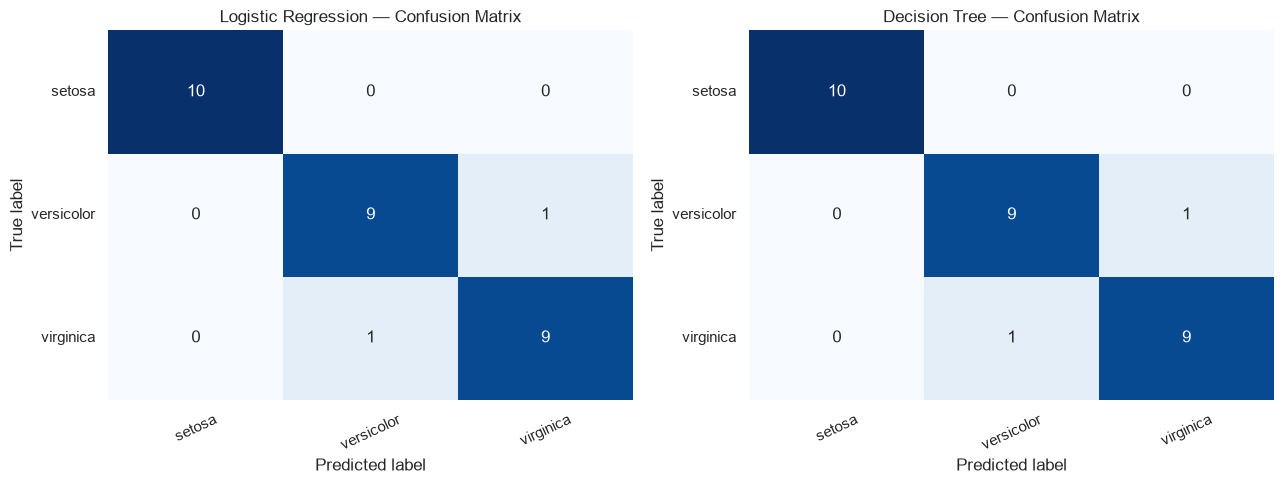

In [11]:
class_labels = sorted(y.unique())

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, (name, y_pred) in zip(axes, predictions.items()):
    cm = confusion_matrix(y_test, y_pred, labels=class_labels)
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
        xticklabels=class_labels, yticklabels=class_labels
    )
    ax.set_title(f"{name} — Confusion Matrix")
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.tick_params(axis="x", rotation=25)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.show()

## 10. Compare benchmark metrics visually

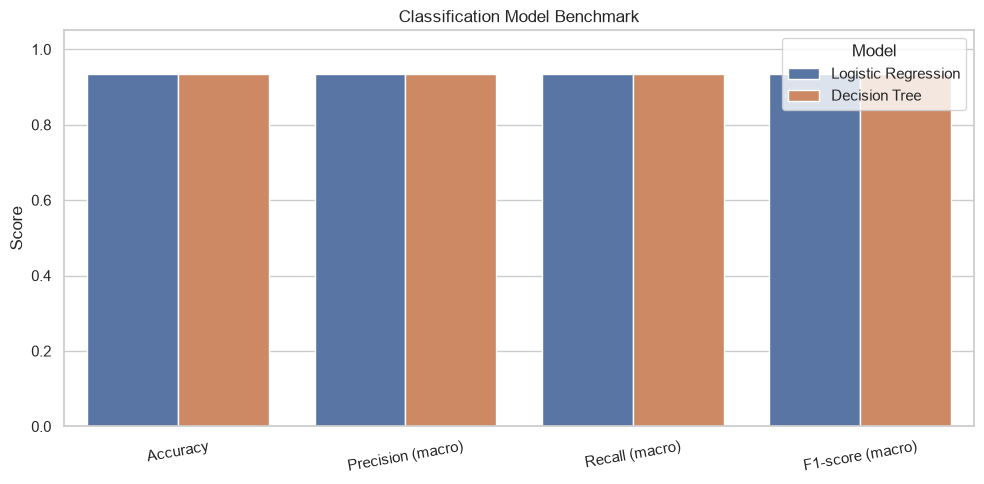

In [12]:
metrics_to_plot = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1-score (macro)"]
results_long = results_df.reset_index().melt(
    id_vars="Model", value_vars=metrics_to_plot,
    var_name="Metric", value_name="Score"
)

plt.figure(figsize=(10, 5))
sns.barplot(data=results_long, x="Metric", y="Score", hue="Model")
plt.ylim(0, 1.05)
plt.title("Classification Model Benchmark")
plt.ylabel("Score")
plt.xlabel("")
plt.xticks(rotation=10)
plt.legend(title="Model")
plt.tight_layout()
plt.show()

## 11. Decision-boundary visualization

A decision boundary is easiest to plot in two dimensions. Here we use **petal length and petal width**. These plots are illustrative projections using only those two features, so their scores need not match the four-feature models above.

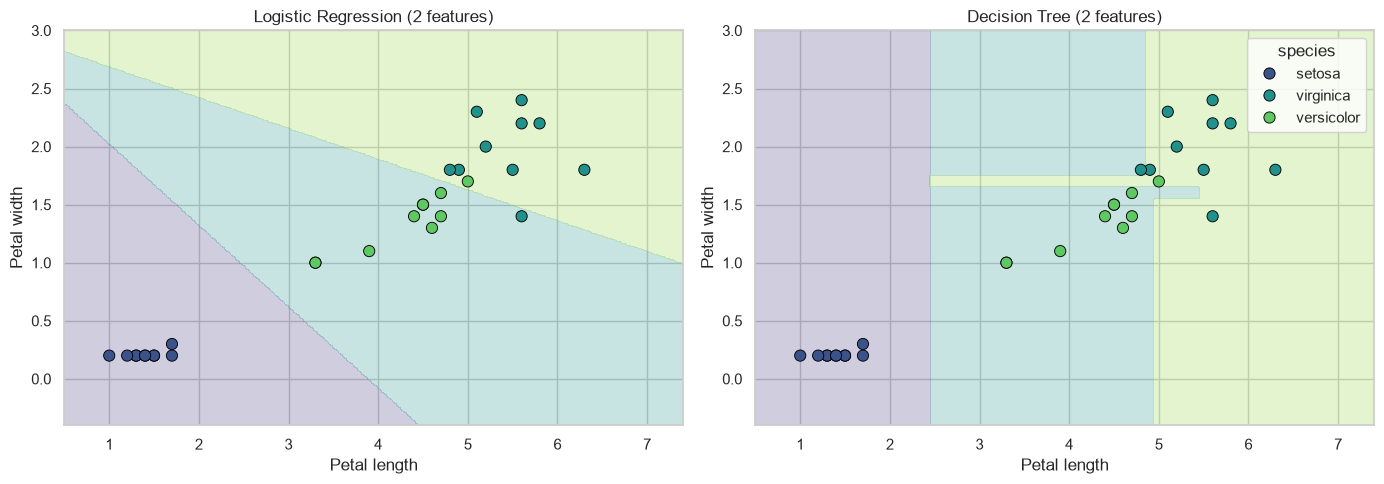

In [13]:
feature_pair = ["petal_length", "petal_width"]
X_2d = df[feature_pair]
y_2d = df["species"]

X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d, y_2d,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_2d
)

boundary_models = {
    "Logistic Regression (2 features)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE))
    ]),
    "Decision Tree (2 features)": Pipeline([
        ("scaler", StandardScaler()),
        ("classifier", DecisionTreeClassifier(random_state=RANDOM_STATE))
    ])
}

for model in boundary_models.values():
    model.fit(X2_train, y2_train)

x_min, x_max = X_2d[feature_pair[0]].min() - 0.5, X_2d[feature_pair[0]].max() + 0.5
y_min, y_max = X_2d[feature_pair[1]].min() - 0.5, X_2d[feature_pair[1]].max() + 0.5
xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)
grid = pd.DataFrame(
    np.c_[xx.ravel(), yy.ravel()],
    columns=feature_pair
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (name, model) in zip(axes, boundary_models.items()):
    grid_pred = model.predict(grid)
    class_to_num = {label: i for i, label in enumerate(sorted(y_2d.unique()))}
    Z = np.array([class_to_num[label] for label in grid_pred]).reshape(xx.shape)

    ax.contourf(xx, yy, Z, alpha=0.25, cmap="viridis", levels=np.arange(-0.5, len(class_to_num) + 0.5, 1))
    sns.scatterplot(
        data=pd.DataFrame({feature_pair[0]: X2_test[feature_pair[0]].values,
                           feature_pair[1]: X2_test[feature_pair[1]].values,
                           "species": y2_test.values}),
        x=feature_pair[0], y=feature_pair[1], hue="species",
        palette="viridis", edgecolor="black", s=65, ax=ax, legend=(ax is axes[1])
    )
    ax.set_title(name)
    ax.set_xlabel("Petal length")
    ax.set_ylabel("Petal width")

plt.tight_layout()
plt.show()

## 12. Final model selection

In [14]:
best_model_name = results_df["F1-score (macro)"].idxmax()
best_f1 = results_df.loc[best_model_name, "F1-score (macro)"]

print(f"Best model by macro F1-score on this test split: {best_model_name}")
print(f"Macro F1-score: {best_f1:.3f}")
print("\\nBenchmark table:")
display(results_df.round(3))

print(
    "\\nNote: The Iris dataset is small and relatively easy. "
    "Results can vary with a different split. For a stronger comparison, "
    "use cross-validation and tune hyperparameters on training data only."
)

Best model by macro F1-score on this test split: Logistic Regression
Macro F1-score: 0.933
\nBenchmark table:


,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.933,0.933,0.933,0.933
Decision Tree,0.933,0.933,0.933,0.933


\nNote: The Iris dataset is small and relatively easy. Results can vary with a different split. For a stronger comparison, use cross-validation and tune hyperparameters on training data only.


## 13. Conclusion

In this task, we:
1. Loaded and explored the Iris dataset.
2. Split the data into training and test sets using an 80/20 stratified split.
3. Applied `StandardScaler` within Scikit-Learn pipelines to prevent data leakage.
4. Trained Logistic Regression and Decision Tree classifiers.
5. Compared accuracy, macro precision, macro recall, and macro F1-score.
6. Visualized confusion matrices, metric comparisons, and two-feature decision boundaries.

**Interpretation:** Choose the model based on the evaluation metrics and error patterns, not accuracy alone. The confusion matrix shows which flower classes are being confused. Do not claim a model is universally superior based on one small test split.

## 14. Reproducibility
- Python 3.10+ recommended
- Install dependencies with `pip install -r requirements.txt`
- Run all notebook cells from top to bottom
- Keep the random seed fixed for reproducible train/test splitting

### Suggested GitHub repository structure
```text
datheon-task-1-iris-classification/
├── iris_classification_benchmark.ipynb
├── requirements.txt
└── README.md
```
